In [56]:
from v2_data_preparation import process_modis, process_landsat, process_insitu, slice_by_dates
from v2_sensor_fusion import fuse_sensors
from v2_feature_engineering import build_features_dataset, join_datasets, build_features_dataset_v2
from v3_modelling_framework import split_data, define_model_pipeline_and_grid, tune_and_train_model, evaluate_model, predict_dataset, calculate_shap_values

from v2_visualization import (
    obs_data, format_metrics_table, plot_landsat_bands, plot_residuals_boxplot, 
    plot_pred_vs_real, plot_timeseries_results, plot_timeseries_results2, plot_shap)

import shap
import pandas as pd

In [57]:
# -----------------------------
# 1. Study site selection and config
# -----------------------------

study_site = 'SDH1'
start_date = '2000'
end_date = '2026'

if study_site == 'SDH1':
    target = 'SDH1PS01_gw-depth_m'
    insitu_filepath = '../data/processed/in-situ/SDH1_daily-insitu-data.csv'
    modis_filepath = '../data/processed/satellites/SDH1_MT_500m_2000-03_2026-06.csv'
    landsat_filepath = '../data/processed/satellites/SDH1_L_30m_2012-01-01_2026-10-11.csv'

elif study_site == 'SDH2':
    target = 'SDH2PP01_gw-depth_m'
    insitu_filepath = '../data/processed/in-situ/SDH2_daily-insitu-data.csv'
    modis_filepath = '../data/processed/satellites/SDH2_MT_500m_2000-03_2026-06.csv'
    landsat_filepath = '../data/processed/satellites/SDH2_L_30m_2000-02_2026-06.csv'

else:
    print(f'{study_site} not supported as study site')

band_mapping = {
    'blue':  ('blue_mean',  'blue'),
    'green': ('green_mean', 'green'),
    'red':   ('red_mean',   'red'),
    'nir':   ('nir_mean',   'nir'),
    'swir1': ('swir1_mean', 'swir1'),
    'swir2': ('swir2_mean', 'swir2')
}

modis_cols = ['blue', 'green', 'red', 'nir', 'swir1', 'swir2']
landsat_cols = ['blue_mean', 'green_mean', 'red_mean', 'nir_mean', 'swir1_mean', 'swir2_mean']

features = [
    'ndvi',
    'gndvi',
    'ndwi',
    'mndwi',
    'ndmi',
    'ndmi2',
    'str1',
    'str2',
]

In [58]:
# -----------------------------
# 2. Input data preprocessing
# -----------------------------

modis_df = process_modis(
    filepath=modis_filepath,
    start_date=start_date,
    end_date=end_date,
    cols_to_keep=modis_cols,
    outlier_threshold=3.0,
    smooth_window=25
)

landsat_df = process_landsat(
    filepath=landsat_filepath,
    start_date=start_date,
    end_date=end_date,
    cols_to_keep=landsat_cols,
    outlier_threshold=3.0,
    stats_min_points=10
)

insitu_df = process_insitu(
    filepath=insitu_filepath,
    start_date='2024-05-24',
    end_date='2026-06-26',
    cols_to_keep=target,
    outlier_threshold=3.0
    )

<Axes: >

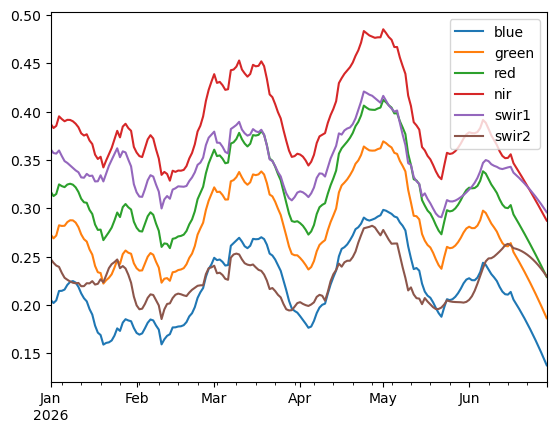

In [59]:
modis_clip = slice_by_dates(modis_df, '2026')
modis_clip.plot()

In [60]:
# -----------------------------
# 3. Daily satellite series
# -----------------------------

sensor_fusion_results = fuse_sensors(
    modis_df=modis_df,
    landsat_df=landsat_df,
    band_mapping=band_mapping,
    test_size=0.3,
    sigma_threshold=3.0,
    verbose_summary=False,
    verbose_plots=False
)

# plot_residuals_boxplot(sensor_fusion_results['residuals'])
# plot_landsat_bands(
#     daily_df=sensor_fusion_results['anchored'],
#     original_df=landsat_df,
#     residuals_df=sensor_fusion_results['residuals_interpolated'],
#     start='2021',
#     end='2026'
# )
# plot_landsat_bands(
#     daily_df=sensor_fusion_results['predicted'],
#     original_df=landsat_df,
#     residuals_df=sensor_fusion_results['residuals'],
#     start='2021',
#     end='2026'
# )

metrics_df = format_metrics_table(sensor_fusion_results['metrics'])
print(metrics_df.to_string())


Processing blue (521 coincident points)
Train - R2: 0.713 | MAE: 0.036 | RMSE: 0.049
Test  - R2: 0.661  | MAE: 0.037  | RMSE: 0.053

Processing green (524 coincident points)
Train - R2: 0.728 | MAE: 0.036 | RMSE: 0.051
Test  - R2: 0.572  | MAE: 0.045  | RMSE: 0.065

Processing red (522 coincident points)
Train - R2: 0.7 | MAE: 0.04 | RMSE: 0.058
Test  - R2: 0.521  | MAE: 0.044  | RMSE: 0.066

Processing nir (525 coincident points)
Train - R2: 0.669 | MAE: 0.04 | RMSE: 0.058
Test  - R2: 0.505  | MAE: 0.048  | RMSE: 0.071

Processing swir1 (525 coincident points)
Train - R2: 0.701 | MAE: 0.041 | RMSE: 0.058
Test  - R2: 0.604  | MAE: 0.045  | RMSE: 0.066

Processing swir2 (525 coincident points)
Train - R2: 0.741 | MAE: 0.04 | RMSE: 0.054
Test  - R2: 0.645  | MAE: 0.044  | RMSE: 0.064
                 r2    mae   rmse
band  subset                     
blue  train   0.713  0.036  0.049
      test    0.661  0.037  0.053
green train   0.728  0.036  0.051
      test    0.572  0.045  0.065
re

In [61]:
# -----------------------------
# 4. Predictors and target processing
# -----------------------------

# features_dataset, cc_report, pca_model = build_features_dataset(
#     remote_df=sensor_fusion_results['predicted'],
#     insitu_df=insitu_df,
#     target_col=target,
#     spectral_bands_cols=modis_cols,
#     pca_components=2,
#     verbose_pca=True,
#     rolling_windows=[7],
#     rolling_stats=['mean'],
#     max_cc_lag=8,
#     min_corr_thresh=0.1,
#     top_k_lags=5,
#     random_state=42
# )

features_dataset = build_features_dataset_v2(
    remote_df=sensor_fusion_results['predicted'],
    spectral_bands_cols=modis_cols,
    pca_components=3,
    verbose_pca=True,
    past_lags=[0],
    future_lags=[0],
    random_state=42
)

training_df = join_datasets(
    df1=insitu_df[[target]],
    df2=features_dataset,
    how='inner'
    )


print(f'\nTraining dataset: {training_df.shape[0]} rows, {training_df.shape[1]} columns')


--- PCA Evaluation ---
Component 1 explains: 60.36% of the variance
Component 2 explains: 34.12% of the variance
Component 3 explains: 3.90% of the variance
Total variance retained: 98.38%

Contribution per feature:
        PC_1   PC_2   PC_3
ndvi   0.374 -0.319 -0.128
gndvi  0.360 -0.355 -0.257
ndwi  -0.360  0.355  0.257
mndwi  0.093  0.589 -0.097
ndmi   0.328  0.404 -0.274
ndmi2  0.351  0.349 -0.387
str1   0.423  0.043  0.625
str2   0.427  0.111  0.476

Training dataset: 764 rows, 8 columns


In [62]:
# -----------------------------
# 5. Model training and evaluation
# -----------------------------

data_split = split_data(
    df=training_df,
    target=target,
    test_start_date='2025-05-23',    # 2025-05-18
    chronological_order=False
)

X_train = data_split['X_train']
X_test = data_split['X_test']
y_train = data_split['y_train']
y_test = data_split['y_test']

opt_results = tune_and_train_model(
    X_train=X_train,
    y_train=y_train,
    model_type='rf',
    n_splits=3,
    max_train_size=None,
    test_size=30,
    gap=1,
    nested_cv=True
)
print("\n--- Hiperparámetros seleccionados ---")
print('Best CV RMSE:')
print(opt_results['best_cv_rmse'])
for parameter_name, parameter_value in opt_results[
    "best_hyperparameters"
].items():
    print(f"{parameter_name}: {parameter_value}")

best_pipeline = opt_results["best_pipeline"]

y_pred_test, y_pred_train, metrics_test, metrics_train = evaluate_model(
    model=best_pipeline,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test,
)

predictions_df = predict_dataset(
    df=training_df,
    model=best_pipeline,
    target=target
)

Training samples: 399 | Testing samples: 365

--- Hiperparámetros seleccionados ---
Best CV RMSE:
0.05474318169426312
regressor__max_depth: 15
regressor__min_samples_split: 10
regressor__n_estimators: 100

--- Training performance ---
R²:   0.984
RMSE:   0.013
MAE:   0.009
PBIAS:   -0.065

--- Testing performance ---
R²:   0.702
RMSE:   0.074
MAE:   0.061
PBIAS:   -0.514


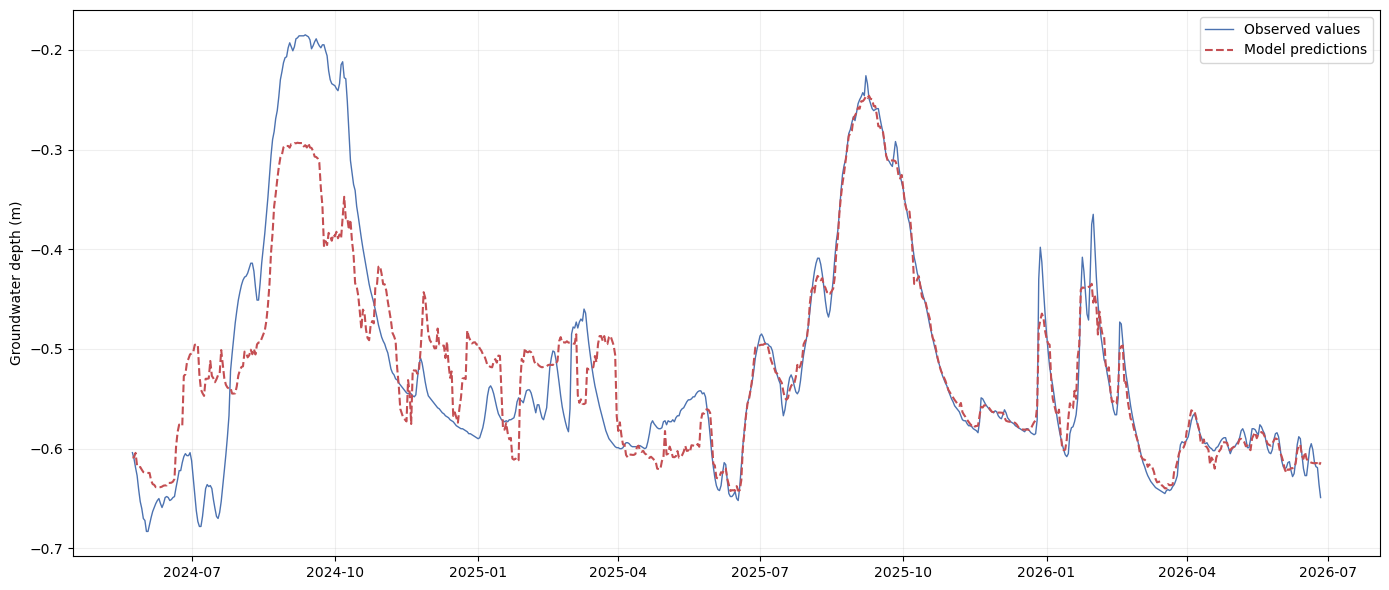

In [63]:
plot_timeseries_results(df=predictions_df)

In [64]:
# shap_values = None

# shap_values = calculate_shap_values(
#     model=best_pipeline,
#     X=X_test,
#     sample_size=None
# )